# Junction resistance: from the wire-limited to the junction-limited network

Every result of the dissertation so far treats a crossing of two sticks as an ideal contact:
one node, no resistance. Real films are not like that. In a silver-nanowire film the wire-to-wire
junction resistance is comparable to the resistance of a wire (Bellew et al. 2015), and in a
carbon-nanotube film the junctions dominate outright (Nirmalraj et al. 2009), with the
metallic/semiconducting junctions orders of magnitude higher than the rest (Fuhrer et al. 2000).
The literature parametrizes this by the junction-to-stick ratio (Zezelj & Stankovic 2012) and
finds the network resistance roughly additive in the wire and junction terms (Benda et al. 2019).

This notebook adds a junction resistance to the model of `run_full_pipeline` **without changing
the pipeline**: every crossing $n$ of sticks $i$ and $j$ becomes two nodes, $(n,i)$ and $(n,j)$,
joined by a junction edge of resistance $R_j$; the stick segments keep their length-based
resistance $R_0 L$ and run between the copies on their own stick (`utils/junction_model.py`).
The one new parameter is

$$\rho = \frac{R_j}{R_0\, a},$$

a junction over one whole stick. $\rho = 0$ is the wire-limited model and must reproduce every
stored $R_{\mathrm{eff}}$ exactly, which is the validation.

Three variants, in order:

1. **Uniform** $R_j$ — the crossover $R_{\mathrm{eff}}(\rho)$ on the 990 networks of the
   near-threshold sweep (computed on Apuana by `cluster/run_junction_task.py`, loaded here);
   the slope $\beta = \mathrm{d}R_{\mathrm{eff}}/\mathrm{d}R_j$; the red junctions.
2. **Distributed** $R_j$ — lognormal around the same mean; does the spread matter?
3. **Bimodal** $R_j$ — metallic/semiconducting sticks, with the mixed junctions $\kappa$ times
   more resistive; the nanotube-film picture.

Variants 2 and 3 are computed here on a small subset (they are cheap once the networks exist).


---
## 1. Setup and imports

In [1]:
import sys
import os
import glob
import json
import time
import numpy as np
import matplotlib.pyplot as plt

try:
    from google.colab import drive
    drive.mount('/content/drive')
    utils_path = "/content/drive/MyDrive/ColabProject/utils"
    cluster_dir = "/content/drive/MyDrive/ColabProject/cluster"
    print("Environment: Google Colab")
except ImportError:
    utils_path = os.path.abspath(os.path.join(os.getcwd(), "..", "utils"))
    cluster_dir = os.path.abspath(os.path.join(os.getcwd(), "..", "cluster"))
    print("Environment: Local")

for p in (utils_path, cluster_dir):
    if p not in sys.path:
        sys.path.append(p)

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)   # numpy's matmul warnings from the dense solver on macOS

from pipeline_utils import generate_percolating_network, distance_dependent_impedance, stable_seed
from junction_model import build_junction_network, solve_two_terminal, junction_resistances, red_bonds
from run_critical_sweep_task import build_plan, R0, MAX_ATTEMPTS, DRAW_BUDGET

print(f"R0 = {R0}; {len(build_plan())} points in the near-threshold plan")

Environment: Local
R0 = 1000.0; 33 points in the near-threshold plan


---
## 2. The junction graph on a case that can be solved by hand

Three sticks in series: stick A from a crossing in the source strip to a crossing with stick B,
stick B up to a crossing with stick C, stick C to a crossing in the drain strip. The current has
to change stick twice, so

$$R_{\mathrm{eff}} = R_0 (0.45 + 0.40 + 0.45) + 2 R_j .$$

The two crossings inside the strips also have junctions, but the electrode shorts them.


In [2]:
hand = {"intersections_points": [(0.05, 0.3), (0.95, 0.7), (0.5, 0.3), (0.5, 0.7)],
        "graph": [(0, 1), (3, 4), (1, 2), (2, 3)],                 # the two sticks at each crossing
        "filtered_segment_edge_list": [(1, (0, 2)), (2, (2, 3)), (3, (3, 1))]}   # (stick, (crossing, crossing))
net_hand = build_junction_network(hand)
for Rj in (0.0, 100.0, 1e4):
    sol = solve_two_terminal(net_hand, R0, Rj)
    print(f"R_j = {Rj:8.1f}: R_eff = {sol['R_eff']:10.4f}   expected {R0*1.3 + 2*Rj:10.4f}")
rs, rj = red_bonds(solve_two_terminal(net_hand, R0, 100.0))
print("red segments:", rs.tolist(), "  red junctions by crossing:", dict(zip(net_hand["crossings"], rj.tolist())))

R_j =      0.0: R_eff =  1300.0000   expected  1300.0000
R_j =    100.0: R_eff =  1500.0000   expected  1500.0000
R_j =  10000.0: R_eff = 21300.0000   expected 21300.0000
red segments: [True, True, True]   red junctions by crossing: {0: False, 1: False, 2: True, 3: True}


---
## 3. Validation on real networks: $\rho \to 0$ reproduces the wire-limited model

`solve_two_terminal(..., contract_junctions=True)` identifies the two copies of every crossing,
which is the wire-limited graph rebuilt from the same stored edge list; it must agree with
`distance_dependent_impedance` to floating-point precision. A tiny but finite $R_j$ must agree
to the order of $R_j / R_{\mathrm{eff}}$.


In [3]:
worst_contract = worst_limit = 0.0
for N, a in [(150, 0.2), (250, 0.2), (267, 0.15)]:
    np.random.seed(stable_seed(N, round(a, 3), "critical"))
    res, _ = generate_percolating_network(N, a, k_uniform=R0, max_attempts=MAX_ATTEMPTS)
    ref = distance_dependent_impedance(res, R0)["impedance"]
    net = build_junction_network(res)
    t0 = time.time()
    Rc = solve_two_terminal(net, R0, 0.0)["R_eff"]                 # all-zero R_j -> contraction
    Rl = solve_two_terminal(net, R0, 1e-9 * R0 * a)["R_eff"]
    dt = time.time() - t0
    worst_contract = max(worst_contract, abs(Rc - ref) / ref)
    worst_limit = max(worst_limit, abs(Rl - ref) / ref)
    print(f"N={N:4d} a={a}: crossings {net['n_cross']:5d} -> {len(net['coords']):5d} nodes;  "
          f"stored {ref:9.3f}  contracted {Rc:9.3f}  R_j=1e-9 R0 a: {Rl:9.3f}   ({dt*500:.0f} ms per solve)")
print(f"\nworst relative disagreement: contracted {worst_contract:.1e}, small-R_j limit {worst_limit:.1e}")
assert worst_contract < 1e-9

N= 150 a=0.2: crossings   275 ->   550 nodes;  stored   253.897  contracted   253.897  R_j=1e-9 R0 a:   253.897   (1 ms per solve)


N= 250 a=0.2: crossings   848 ->  1696 nodes;  stored   101.482  contracted   101.482  R_j=1e-9 R0 a:   101.482   (1 ms per solve)


N= 267 a=0.15: crossings   476 ->   952 nodes;  stored   299.832  contracted   299.832  R_j=1e-9 R0 a:   299.833   (1 ms per solve)

worst relative disagreement: contracted 6.2e-13, small-R_j limit 3.0e-06


---
# Part A — Uniform junction resistance (variant 1)

Computed on Apuana by `cluster/run_junction_task.py`: the 33 points of the near-threshold sweep,
30 realizations each, regenerated from their seeds and checked against `critical_sweep_results/`,
solved at $\rho \in \{0, 0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100\}$. Per network and $\rho$ it
stores $R_{\mathrm{eff}}$, the resistance of the red segments and of the red junctions, and the
power dissipated in all junctions; the red-bond sets are topological (independent of $\rho > 0$)
and are stored once. `cluster/junction_analysis.py` turns the files into the numbers and figures
of the thesis; its functions are reused here.


In [4]:
import junction_analysis as ja

pts = ja.load(os.path.join(cluster_dir, "junction_results"))
assert pts, "junction_results/ is empty: run cluster/run_junction_array.sbatch first"
rows = [ja.per_point(p) for p in pts]
rhos = rows[0]["rhos"]; sizes = sorted(set(r["a"] for r in rows), reverse=True)
print(f"{len(pts)} points, {sum(p['n'] for p in pts)} realizations, rho in {rhos}")

33 points, 990 realizations, rho in [0.0, 0.01, 0.03, 0.1, 0.3, 1.0, 3.0, 10.0, 30.0, 100.0]


### A.1 The crossover

$R_{\mathrm{eff}}(\rho)/R_{\mathrm{eff}}(0)$ against $\rho$. The horizontal line is a doubling;
the $\rho^*$ at which it is crossed is where the junctions contribute as much as the wires.


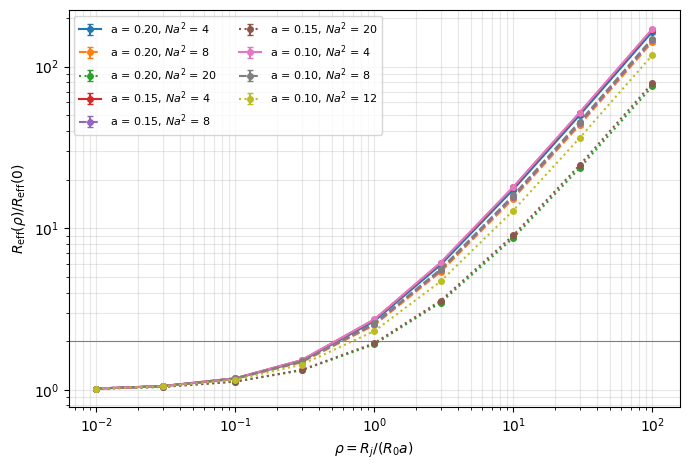

    a  Na2  R(1)/R(0)  R(100)/R(0)   rho*
 0.20    4       2.66          164   0.52
 0.20    5       2.68          164   0.51
 0.20    6       2.61          155   0.53
 0.20    7       2.63          155   0.51
 0.20    8       2.51          142   0.56
 0.20    9       2.47          136   0.58
 0.20   10       2.35          123   0.64
 0.20   12       2.28          115   0.68
 0.20   14       2.16          101   0.79
 0.20   16       2.08           93   0.88
 0.20   18       1.99           83   0.99
 0.20   20       1.91           75   1.07
 0.15    4       2.72          170   0.49
 0.15    5       2.66          162   0.51
 0.15    6       2.68          163   0.50
 0.15    7       2.61          155   0.52
 0.15    8       2.55          146   0.54
 0.15    9       2.49          138   0.56
 0.15   10       2.38          127   0.61
 0.15   12       2.28          115   0.68
 0.15   14       2.17          103   0.77
 0.15   16       2.06           92   0.90
 0.15   18       2.00           86

In [5]:
fig, ax = plt.subplots(figsize=(7, 4.8))
styles = {4: "-", 8: "--", 12: ":", 20: ":"}
rho_pos = np.array(rhos[1:])
for a in sizes:
    for r in sorted([r for r in rows if r["a"] == a], key=lambda r: r["x"]):
        xt = r["x_target"]
        if xt not in (4, 8, 20) and not (a == 0.10 and xt == 12):
            continue
        ax.errorbar(rho_pos, r["ratio_mean"][1:], yerr=r["ratio_sem"][1:], fmt="o" + styles[xt], ms=4, capsize=2,
                    label=f"a = {a:.2f}, $Na^2$ = {xt}")
ax.axhline(2, color="gray", lw=0.8); ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$\rho = R_j/(R_0 a)$"); ax.set_ylabel(r"$R_{\mathrm{eff}}(\rho)/R_{\mathrm{eff}}(0)$")
ax.legend(fontsize=8, ncol=2); ax.grid(True, alpha=0.3, which="both"); plt.tight_layout(); plt.show()

print(f"{'a':>5} {'Na2':>4} {'R(1)/R(0)':>10} {'R(100)/R(0)':>12} {'rho*':>6}")
for a in sizes:
    for r in sorted([r for r in rows if r["a"] == a], key=lambda r: r["x"]):
        print(f"{a:5.2f} {r['x_target']:4d} {r['ratio_mean'][rhos.index(1.0)]:10.2f} {r['ratio_mean'][-1]:12.0f} {r['rho_star']:6.2f}")

The curves at a given $Na^2$ coincide across the three boxes: $\rho^* \approx 0.5$ at
$Na^2 = 4$ in all three, $\approx 0.68$ at $12$, $\approx 1.05$ at $20$. The crossover depends
on $Na^2$ alone — a junction matters once it costs about half a stick near the threshold, and
about one stick in the denser networks, where it has more parallel company.

### A.2 The slope $\beta = \mathrm{d}R_{\mathrm{eff}}/\mathrm{d}R_j$

Benda et al. write $R_{\mathrm{eff}}$ as additive in the wire and junction resistances. On a
fixed network that is the statement that $R_{\mathrm{eff}}$ is linear in $R_j$, with a slope
$\beta$ that counts the junctions in series along the effective path. Rayleigh's law only makes
$R_{\mathrm{eff}}(R_j)$ increasing and concave, so the drift of $\beta$ across $\rho$ measures
how far from additive the network is.


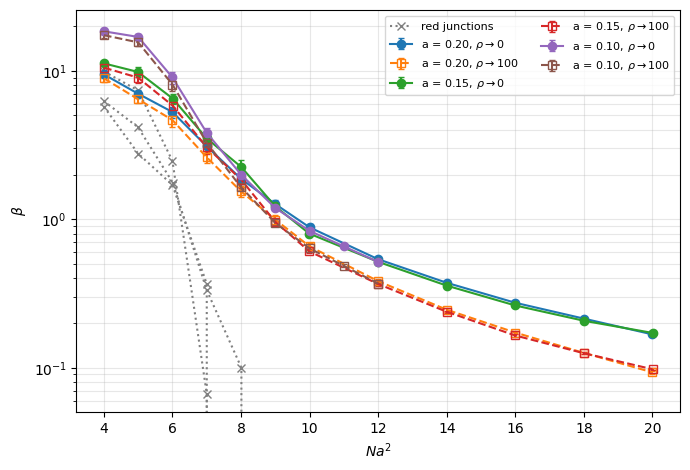

beta at the lowest and highest rho interval; ratio 1 would be exactly additive
  a=0.20 Na2= 4:   9.45 ->   8.90  ratio 0.94   red junctions 5.7
  a=0.20 Na2= 6:   5.27 ->   4.65  ratio 0.88   red junctions 1.7
  a=0.20 Na2= 8:   1.87 ->   1.54  ratio 0.82   red junctions 0.0
  a=0.20 Na2=12:   0.54 ->   0.38  ratio 0.71   red junctions 0.0
  a=0.20 Na2=20:   0.17 ->   0.09  ratio 0.56   red junctions 0.0
  a=0.15 Na2= 4:  11.21 ->  10.49  ratio 0.94   red junctions 6.2
  a=0.15 Na2= 6:   6.50 ->   5.82  ratio 0.90   red junctions 1.8
  a=0.15 Na2= 8:   2.24 ->   1.84  ratio 0.82   red junctions 0.1
  a=0.15 Na2=12:   0.52 ->   0.37  ratio 0.71   red junctions 0.0
  a=0.15 Na2=20:   0.17 ->   0.10  ratio 0.57   red junctions 0.0
  a=0.10 Na2= 4:  18.44 ->  17.37  ratio 0.94   red junctions 9.9
  a=0.10 Na2= 6:   9.01 ->   8.08  ratio 0.90   red junctions 2.5
  a=0.10 Na2= 8:   2.00 ->   1.64  ratio 0.82   red junctions 0.0
  a=0.10 Na2=12:   0.52 ->   0.37  ratio 0.71   red junctions 0

In [6]:
fig, ax = plt.subplots(figsize=(7, 4.8))
for a in sizes:
    rs = sorted([r for r in rows if r["a"] == a], key=lambda r: r["x"])
    ax.errorbar([r["x"] for r in rs], [r["beta_mean"][0] for r in rs], yerr=[r["beta_sem"][0] for r in rs], fmt="o-", capsize=2, label=f"a = {a:.2f}, $\\rho \\to 0$")
    ax.errorbar([r["x"] for r in rs], [r["beta_mean"][-1] for r in rs], yerr=[r["beta_sem"][-1] for r in rs], fmt="s--", mfc="none", capsize=2, label=f"a = {a:.2f}, $\\rho \\to 100$")
    ax.plot([r["x"] for r in rs], [r["red_jun"] for r in rs], "x:", color="gray", label="red junctions" if a == sizes[0] else None)
ax.set_yscale("log"); ax.set_xlabel(r"$Na^2$"); ax.set_ylabel(r"$\beta$"); ax.legend(fontsize=8, ncol=2); ax.grid(True, alpha=0.3, which="both")
plt.tight_layout(); plt.show()

print("beta at the lowest and highest rho interval; ratio 1 would be exactly additive")
for a in sizes:
    for r in sorted([r for r in rows if r["a"] == a], key=lambda r: r["x"]):
        if r["x_target"] in (4, 6, 8, 12, 20):
            print(f"  a={a:.2f} Na2={r['x_target']:2d}: {r['beta_mean'][0]:6.2f} -> {r['beta_mean'][-1]:6.2f}  ratio {r['beta_mean'][-1]/r['beta_mean'][0]:.2f}   red junctions {r['red_jun']:.1f}")

Near the threshold the network is additive to within 6% over four decades of $\rho$, and
$\beta \approx 9$ to $18$ junctions in series, of which $6$ to $10$ are red (every route crosses
them) and the rest sit inside the blobs. At $Na^2 = 20$ the slope halves between $\rho = 0.03$
and $30$: the current rearranges onto the routes with fewest junctions as they get expensive, and
$\beta \approx 0.1$ says ten routes share each junction.

### A.3 Red junctions and the share of $R_{\mathrm{eff}}$ they carry

A junction is red when every source–drain route crosses from one stick to the other at that
crossing — the cut vertices of the wire-limited graph at which the current changes stick.


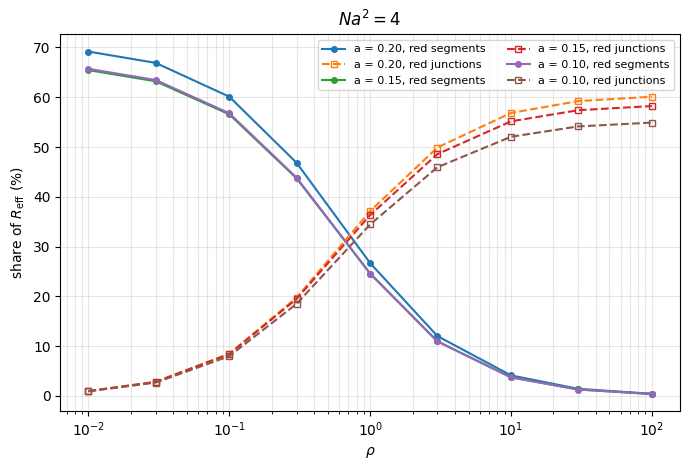

a=0.20: red segments 9.9 +- 0.7, red junctions 5.7 +- 0.6; junction share of R_eff 37% at rho=1, 60% at rho=100; all junctions dissipate 61% / 99%
a=0.15: red segments 10.8 +- 0.6, red junctions 6.2 +- 0.4; junction share of R_eff 36% at rho=1, 58% at rho=100; all junctions dissipate 62% / 99%
a=0.10: red segments 17.4 +- 1.2, red junctions 9.9 +- 0.8; junction share of R_eff 34% at rho=1, 55% at rho=100; all junctions dissipate 62% / 99%


In [7]:
fig, ax = plt.subplots(figsize=(7, 4.8))
for a in sizes:
    r = next(r for r in rows if r["a"] == a and r["x_target"] == 4)
    ax.plot(rho_pos, 100 * np.array(r["seg_share"][1:]), "o-", ms=4, label=f"a = {a:.2f}, red segments")
    ax.plot(rho_pos, 100 * np.array(r["jun_share"][1:]), "s--", ms=4, mfc="none", label=f"a = {a:.2f}, red junctions")
ax.set_xscale("log"); ax.set_xlabel(r"$\rho$"); ax.set_ylabel(r"share of $R_{\mathrm{eff}}$ (%)"); ax.set_title(r"$Na^2 = 4$")
ax.legend(fontsize=8, ncol=2); ax.grid(True, alpha=0.3, which="both"); plt.tight_layout(); plt.show()

for r in rows:
    if r["x_target"] == 4:
        k1 = rhos.index(1.0)
        print(f"a={r['a']:.2f}: red segments {r['red_seg']:.1f} +- {r['red_seg_sem']:.1f}, red junctions {r['red_jun']:.1f} +- {r['red_jun_sem']:.1f}; "
              f"junction share of R_eff {100*r['jun_share'][k1]:.0f}% at rho=1, {100*r['jun_share'][-1]:.0f}% at rho=100; "
              f"all junctions dissipate {100*r['jun_diss'][k1]:.0f}% / {100*r['jun_diss'][-1]:.0f}%")

---
# Part B — Distributed junction resistance (variant 2)

Same networks, same mean, but each junction drawn from a lognormal,
$R_j = \bar R_j\, e^{\sigma z - \sigma^2/2}$ with $z \sim \mathcal N(0,1)$ (so the arithmetic
mean is $\bar R_j$ for every $\sigma$). The question is whether the spread changes
$R_{\mathrm{eff}}$ at fixed mean. Two limits are known in advance: a chain of red junctions in
series depends only on the sum, so the mean, and near the threshold the ratio should be one;
many junctions in parallel average the *conductance*, which Jensen's inequality makes larger than
the conductance of the mean, so in dense networks the ratio should fall below one, increasingly
with $\sigma$ and with $\rho$.

A subset: $a = 0.2$ at $Na^2 \in \{4, 8, 12\}$, ten realizations each, regenerated from the
sweep's seeds (the same first ten networks the cluster used).


In [8]:
SUBSET = [(0.2, 4), (0.2, 8), (0.2, 12)]
N_SUB = 10
plan = build_plan()

def regenerate(a, x_target, n):
    pt = next(p for p in plan if p["a"] == a and p["x_target"] == x_target)
    np.random.seed(stable_seed(pt["N"], round(a, 3), "critical"))
    nets = []
    draws = 0
    while len(nets) < n and draws < DRAW_BUDGET:
        res, att = generate_percolating_network(pt["N"], a, k_uniform=R0, max_attempts=MAX_ATTEMPTS)
        draws += att
        if res is not None:
            nets.append(build_junction_network(res))
    return nets

t0 = time.time()
subset_nets = {key: regenerate(*key, N_SUB) for key in SUBSET}
print({k: [len(n['coords']) for n in v] for k, v in subset_nets.items()})
print(f"regenerated in {time.time()-t0:.0f} s")

{(0.2, 4): [186, 162, 192, 140, 90, 114, 194, 180, 240, 228], (0.2, 8): [1058, 1014, 866, 1118, 902, 1038, 944, 828, 980, 952], (0.2, 12): [2170, 2336, 2306, 2330, 2162, 2202, 2540, 2090, 2206, 2312]}
regenerated in 18 s


In [9]:
SIGMAS = [0.0, 0.5, 1.0, 1.5]
RHO_BAR = [0.1, 1.0, 10.0]
N_DRAWS = 5      # independent junction draws per network and sigma
rng = np.random.default_rng(2026)

print(f"{'Na2':>4} {'rho_bar':>8} | " + " ".join(f"sigma={s:<4}" for s in SIGMAS) + "     (R_eff distributed / R_eff uniform, mean +- sem over networks and draws)")
dist_results = {}
for (a, xt), nets in subset_nets.items():
    for rb in RHO_BAR:
        Rbar = rb * R0 * a
        line = []
        for sg in SIGMAS:
            ratios = []
            for net in nets:
                R_uniform = solve_two_terminal(net, R0, Rbar)["R_eff"]
                for _ in range(N_DRAWS if sg > 0 else 1):
                    Rj = Rbar * np.exp(sg * rng.standard_normal(net["n_cross"]) - sg**2 / 2)
                    ratios.append(solve_two_terminal(net, R0, Rj)["R_eff"] / R_uniform)
            ratios = np.array(ratios)
            dist_results[(xt, rb, sg)] = (ratios.mean(), ratios.std(ddof=1) / np.sqrt(len(ratios)) if len(ratios) > 1 else 0.0)
            line.append(f"{ratios.mean():.3f}+-{dist_results[(xt, rb, sg)][1]:.3f}")
        print(f"{xt:4d} {rb:8.1f} | " + "  ".join(line))

 Na2  rho_bar | sigma=0.0  sigma=0.5  sigma=1.0  sigma=1.5      (R_eff distributed / R_eff uniform, mean +- sem over networks and draws)
   4      0.1 | 1.000+-0.000  0.998+-0.003  0.981+-0.006  1.006+-0.023
   4      1.0 | 1.000+-0.000  0.984+-0.015  0.928+-0.027  1.008+-0.107
   4     10.0 | 1.000+-0.000  0.940+-0.019  0.899+-0.037  0.686+-0.060


   8      0.1 | 1.000+-0.000  0.997+-0.002  0.979+-0.005  0.963+-0.004
   8      1.0 | 1.000+-0.000  0.943+-0.006  0.819+-0.010  0.707+-0.013


   8     10.0 | 1.000+-0.000  0.898+-0.008  0.697+-0.019  0.414+-0.012


  12      0.1 | 1.000+-0.000  0.994+-0.001  0.975+-0.002  0.954+-0.002


  12      1.0 | 1.000+-0.000  0.937+-0.003  0.806+-0.004  0.677+-0.004


  12     10.0 | 1.000+-0.000  0.870+-0.005  0.578+-0.006  0.339+-0.004


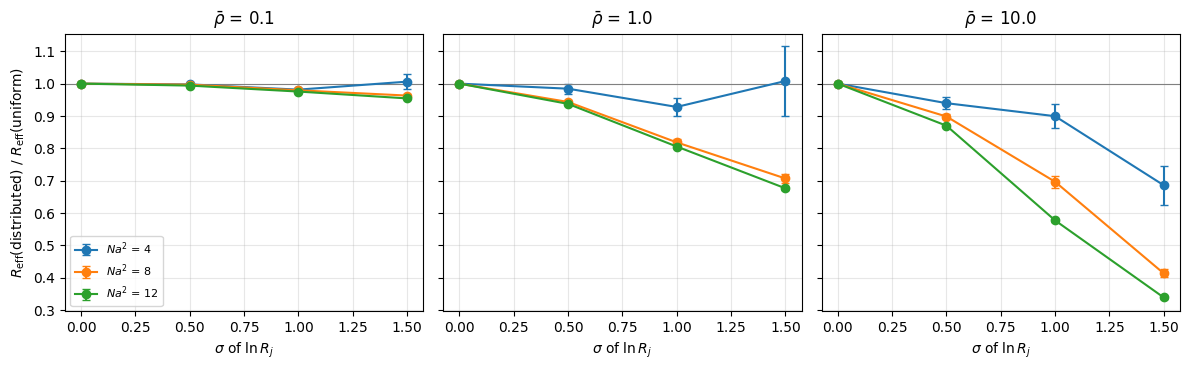

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.8), sharey=True)
for ax, rb in zip(axes, RHO_BAR):
    for (a, xt) in SUBSET:
        m = [dist_results[(xt, rb, sg)][0] for sg in SIGMAS]; e = [dist_results[(xt, rb, sg)][1] for sg in SIGMAS]
        ax.errorbar(SIGMAS, m, yerr=e, fmt="o-", capsize=3, label=f"$Na^2$ = {xt}")
    ax.axhline(1, color="gray", lw=0.8); ax.set_xlabel(r"$\sigma$ of $\ln R_j$"); ax.set_title(rf"$\bar\rho$ = {rb}"); ax.grid(True, alpha=0.3)
axes[0].set_ylabel(r"$R_{\mathrm{eff}}$(distributed) / $R_{\mathrm{eff}}$(uniform)"); axes[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

---
# Part C — Metallic and semiconducting sticks (variant 3)

The nanotube picture. Each stick is metallic with probability $p_m$ (one third, the chirality
statistics) or semiconducting otherwise; a junction between two sticks of the same kind has
resistance $R_j$, a mixed junction $\kappa R_j$, with $\kappa$ from $1$ (variant 1) upward
(Fuhrer et al. 2000 measured the mixed junction orders of magnitude above the others). The
sticks themselves keep the wire model — the semiconducting tubes' own higher resistance is
not included, so this isolates the effect of the junction barrier.

At large $\kappa$ the mixed junctions are effectively open and the film splits into a metallic
and a semiconducting sub-network that must each percolate on their own; with $p_m = 1/3$ the
metallic one needs $\tfrac{1}{3} N a^2 \gtrsim 5.6$, i.e. $Na^2 \gtrsim 17$, and the
semiconducting one $Na^2 \gtrsim 8.5$. Below that, a large $\kappa$ is expected to make the
resistance grow in proportion to $\kappa$: the current has to cross a mixed junction somewhere.


In [11]:
P_METAL = 1.0 / 3.0
KAPPAS = [1.0, 10.0, 100.0, 1000.0]
RHO_C = 1.0
N_ASSIGN = 5     # independent metallic/semiconducting assignments per network

print(f"{'Na2':>4} | " + " ".join(f"kappa={k:<6.0f}" for k in KAPPAS) + "     R_eff(kappa) / R_eff(kappa=1), and share of current through mixed junctions")
bimodal = {}
for (a, xt), nets in subset_nets.items():
    Rj = RHO_C * R0 * a
    line, share_line = [], []
    for kappa in KAPPAS:
        ratios, shares = [], []
        for net in nets:
            base = solve_two_terminal(net, R0, Rj)["R_eff"]
            n_sticks = max(max(s) for s in net["sticks_of"].values()) + 1
            for _ in range(N_ASSIGN):
                metallic = rng.random(n_sticks) < P_METAL
                rule = lambda i, j: Rj * (kappa if metallic[i] != metallic[j] else 1.0)
                sol = solve_two_terminal(net, R0, rule)
                ratios.append(sol["R_eff"] / base)
                mixed = np.array([metallic[i] != metallic[j] for (i, j) in (net["sticks_of"][n] for n in net["crossings"])])
                # dissipation share in mixed junctions
                P_mixed = np.sum(sol["jun_R"][mixed] * sol["I_jun"][mixed] ** 2)
                shares.append(P_mixed / (sol["R_eff"] * sol["I_total"] ** 2))
        bimodal[(xt, kappa)] = (np.mean(ratios), np.std(ratios, ddof=1) / np.sqrt(len(ratios)), np.mean(shares))
        line.append(f"{np.mean(ratios):9.2f}"); share_line.append(f"{100*np.mean(shares):5.0f}%")
    print(f"{xt:4d} | " + "  ".join(line) + "   | mixed-junction dissipation " + " ".join(share_line))

 Na2 | kappa=1      kappa=10     kappa=100    kappa=1000       R_eff(kappa) / R_eff(kappa=1), and share of current through mixed junctions


   4 |      1.00       3.21      25.06     240.14   | mixed-junction dissipation    28%    68%    95%    99%


   8 |      1.00       2.27       8.53      72.82   | mixed-junction dissipation    27%    41%    46%    54%


  12 |      1.00       1.81       2.79       5.17   | mixed-junction dissipation    24%    25%    13%     7%


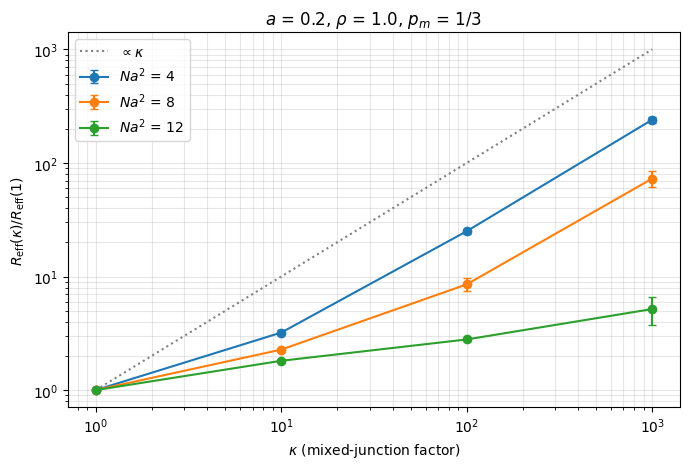

In [12]:
fig, ax = plt.subplots(figsize=(7, 4.8))
for (a, xt) in SUBSET:
    ax.errorbar(KAPPAS, [bimodal[(xt, k)][0] for k in KAPPAS], yerr=[bimodal[(xt, k)][1] for k in KAPPAS], fmt="o-", capsize=3, label=f"$Na^2$ = {xt}")
ax.plot(KAPPAS, KAPPAS, ":", color="gray", label=r"$\propto \kappa$")
ax.set_xscale("log"); ax.set_yscale("log"); ax.set_xlabel(r"$\kappa$ (mixed-junction factor)"); ax.set_ylabel(r"$R_{\mathrm{eff}}(\kappa)/R_{\mathrm{eff}}(1)$")
ax.set_title(rf"$a$ = 0.2, $\rho$ = {RHO_C}, $p_m$ = 1/3"); ax.legend(); ax.grid(True, alpha=0.3, which="both"); plt.tight_layout(); plt.show()

---
## Summary

* $\rho = 0$ reproduces the wire-limited model on every network, and the hand case is exact.
* Uniform $R_j$: the crossover depends on $Na^2$ alone, at $\rho^* \approx 0.5$ near the
  threshold and $\approx 1$ at $Na^2 = 20$; $R_{\mathrm{eff}}$ is additive in $R_j$ to within
  6% near the threshold and concave in the dense networks, where the slope halves over four
  decades; the red junctions are the cut vertices at which the current changes stick, and at
  $\rho \geq 1$ they carry more of the resistance than the red segments.
* Distributed $R_j$: see Part B — the ratio to the uniform network at the same mean.
* Bimodal $R_j$: see Part C — the mixed junctions set the resistance until the sub-networks
  percolate on their own.
